In [2]:
import pandas as pd
import sqlite3
import seaborn as sns
import matplotlib.pyplot as plt

# Predicting Freight Cost

Objective: predict freight cost for a vendor invoice using quantity and dollars, to improve cost forecasting, budgeting, and vendor negotiation

- freight is a non-trivial component of landed cost.
- Poor freitgh estimates distort margin and inventory planning.
- Automating freight estimation helps procurement teams forecast true cost before arrival.

In [19]:
conn = sqlite3.connect("/Users/Maazuddin/Downloads/inventory.db")
tables = pd.read_sql_query("select name from sqlite_master where type = 'table'", conn)

In [20]:
tables

,name
0,purchases
1,purchase_prices
2,vendor_invoice
3,begin_inventory
4,end_inventory


In [124]:
for table in tables['name']:
    print('Table name is:',table)
    df = pd.read_sql_query(f"select * from {table} limit 5", conn)
    display(df)

Table name is: purchases


,InventoryId,Store,Brand,Description,Size,VendorNumber,VendorName,PONumber,PODate,ReceivingDate,InvoiceDate,PayDate,PurchasePrice,Quantity,Dollars,Classification
0,69_MOUNTMEND_8412,69,8412,Tequila Ocho Plata Fresno,750mL,105,ALTAMAR BRANDS LLC,8124,2023-12-21,2024-01-02,2024-01-04,2024-02-16,35.71,6,214.26,1
1,30_CULCHETH_5255,30,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-01,2024-01-07,2024-02-21,9.35,4,37.40,1
2,34_PITMERDEN_5215,34,5215,TGI Fridays Long Island Iced,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-02,2024-01-07,2024-02-21,9.41,5,47.05,1
3,1_HARDERSFIELD_5255,1,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-01,2024-01-07,2024-02-21,9.35,6,56.10,1
4,76_DONCASTER_2034,76,2034,Glendalough Double Barrel,750mL,388,ATLANTIC IMPORTING COMPANY,8169,2023-12-24,2024-01-02,2024-01-09,2024-02-16,21.32,5,106.60,1


Table name is: purchase_prices


,Brand,Description,Price,Size,Volume,Classification,PurchasePrice,VendorNumber,VendorName
0,58,Gekkeikan Black & Gold Sake,12.99,750mL,750,1,9.28,8320,SHAW ROSS INT L IMP LTD
1,62,Herradura Silver Tequila,36.99,750mL,750,1,28.67,1128,BROWN-FORMAN CORP
2,63,Herradura Reposado Tequila,38.99,750mL,750,1,30.46,1128,BROWN-FORMAN CORP
3,72,No. 3 London Dry Gin,34.99,750mL,750,1,26.11,9165,ULTRA BEVERAGE COMPANY LLP
4,75,Three Olives Tomato Vodka,14.99,750mL,750,1,10.94,7245,PROXIMO SPIRITS INC.


Table name is: vendor_invoice


,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval
0,105,ALTAMAR BRANDS LLC,2024-01-04,8124,2023-12-21,2024-02-16,6,214.26,3.47,None
1,4466,AMERICAN VINTAGE BEVERAGE,2024-01-07,8137,2023-12-22,2024-02-21,15,140.55,8.57,None
2,388,ATLANTIC IMPORTING COMPANY,2024-01-09,8169,2023-12-24,2024-02-16,5,106.60,4.61,None
3,480,BACARDI USA INC,2024-01-12,8106,2023-12-20,2024-02-05,10100,137483.78,2935.20,None
4,516,BANFI PRODUCTS CORP,2024-01-07,8170,2023-12-24,2024-02-12,1935,15527.25,429.20,None


Table name is: begin_inventory


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,startDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,8,12.99,2024-01-01
1,1_HARDERSFIELD_60,1,HARDERSFIELD,60,Canadian Club 1858 VAP,750mL,7,10.99,2024-01-01
2,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,6,36.99,2024-01-01
3,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,3,38.99,2024-01-01
4,1_HARDERSFIELD_72,1,HARDERSFIELD,72,No. 3 London Dry Gin,750mL,6,34.99,2024-01-01


Table name is: end_inventory


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,endDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,11,12.99,2024-12-31
1,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,7,36.99,2024-12-31
2,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,7,38.99,2024-12-31
3,1_HARDERSFIELD_72,1,HARDERSFIELD,72,No. 3 London Dry Gin,750mL,4,34.99,2024-12-31
4,1_HARDERSFIELD_75,1,HARDERSFIELD,75,Three Olives Tomato Vodka,750mL,7,14.99,2024-12-31


In [ ]:
# we are selecting only vendor_invoice cause all the required columns are in this table

In [85]:
vendor_df = pd.read_sql_query("select * from vendor_invoice", conn)
vendor_df.head(10)

,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval
0,105,ALTAMAR BRANDS LLC,2024-01-04,8124,2023-12-21,2024-02-16,6,214.26,3.47,None
1,4466,AMERICAN VINTAGE BEVERAGE,2024-01-07,8137,2023-12-22,2024-02-21,15,140.55,8.57,None
2,388,ATLANTIC IMPORTING COMPANY,2024-01-09,8169,2023-12-24,2024-02-16,5,106.60,4.61,None
3,480,BACARDI USA INC,2024-01-12,8106,2023-12-20,2024-02-05,10100,137483.78,2935.20,None
4,516,BANFI PRODUCTS CORP,2024-01-07,8170,2023-12-24,2024-02-12,1935,15527.25,429.20,None
5,2396,BLACK PRINCE DISTILLERY INC,2024-01-08,8191,2023-12-25,2024-02-06,23,234.83,2.30,None
6,1128,BROWN-FORMAN CORP,2024-01-09,8150,2023-12-23,2024-02-19,4684,65403.57,1808.77,None
7,1189,BULLY BOY DISTILLERS,2024-01-09,8171,2023-12-24,2024-02-04,6,132.30,5.29,None
8,1273,CALEDONIA SPIRITS INC,2024-01-06,8172,2023-12-24,2024-02-15,5,146.80,15.53,None
9,11567,CAMPARI AMERICA,2024-01-06,8151,2023-12-23,2024-02-20,1321,12039.71,398.71,None


In [86]:
vendor_df.tail(10)

,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval
5533,90010,VINEXTRA INC,2025-01-04,13659,2024-12-23,2025-02-10,195,2599.66,11.70,None
5534,1587,VINEYARD BRANDS INC,2025-01-03,13625,2024-12-21,2025-02-11,3015,24370.78,109.67,None
5535,90024,VINILANDIA USA,2025-01-05,13642,2024-12-22,2025-02-14,1114,10993.64,52.77,None
5536,1601,VRANKEN AMERICA,2025-01-03,13573,2024-12-18,2025-02-18,430,7984.51,36.73,None
5537,90057,WALPOLE MTN VIEW WINERY,2025-01-07,13660,2024-12-23,2025-02-19,60,694.68,3.20,None
5538,9622,WEIN BAUER INC,2025-01-06,13626,2024-12-21,2025-02-10,90,1563.00,8.60,None
5539,9625,WESTERN SPIRITS BEVERAGE CO,2025-01-10,13661,2024-12-23,2025-02-18,4617,37300.48,186.50,None
5540,3664,WILLIAM GRANT & SONS INC,2025-01-02,13643,2024-12-22,2025-02-04,9848,202815.78,932.95,None
5541,9815,WINE GROUP INC,2025-01-03,13602,2024-12-20,2025-02-08,24747,149007.56,819.54,None
5542,90058,ZORVINO VINEYARDS,2025-01-05,13574,2024-12-18,2025-02-12,437,3608.11,16.60,None


In [28]:
# we are checking the correlation between the columns (if there is relationship between them then we can predict)

In [31]:
vendor_df[['Quantity','Freight','Dollars']].corr()

,Quantity,Freight,Dollars
Quantity,1.000000,0.946550,0.963831
Freight,0.946550,1.000000,0.985141
Dollars,0.963831,0.985141,1.000000


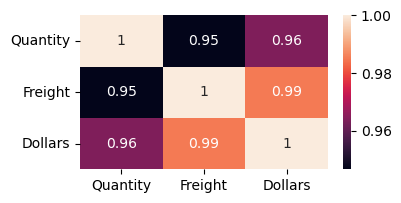

In [32]:
# relationship between quantity,dollars and freight

plt.figure(figsize = (4,2))
sns.heatmap(vendor_df[['Quantity','Freight','Dollars']].corr(),annot = True)
plt.show()

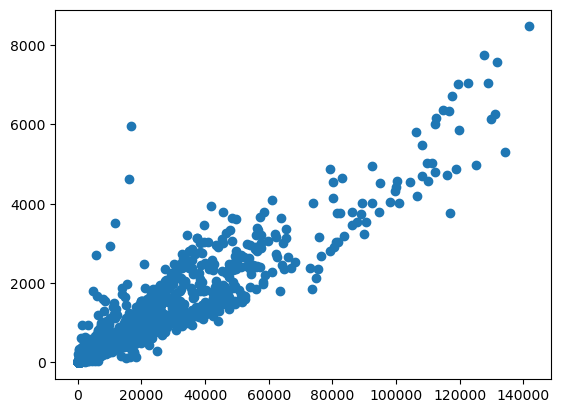

In [33]:
# scatterplot

plt.scatter(vendor_df['Quantity'], vendor_df['Freight'])
plt.show()

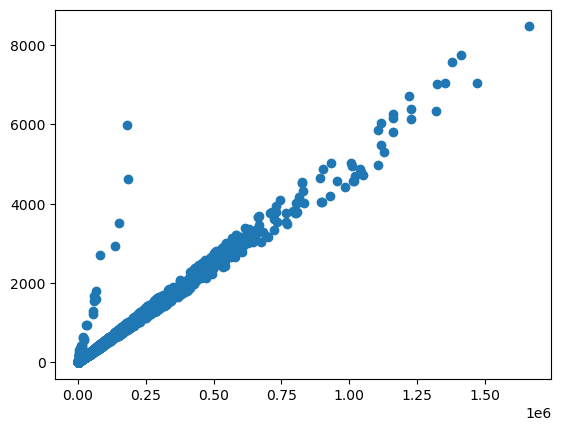

In [34]:
plt.scatter(vendor_df['Dollars'], vendor_df['Freight'])
plt.show()

In [37]:
# checking whether high or low quantity affecting the freight

vendor_df['freight_per_unit'] = vendor_df['Freight'] / vendor_df['Quantity']
vendor_df.head()

,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval,freight_per_unit
0,105,ALTAMAR BRANDS LLC,2024-01-04,8124,2023-12-21,2024-02-16,6,214.26,3.47,None,0.578333
1,4466,AMERICAN VINTAGE BEVERAGE,2024-01-07,8137,2023-12-22,2024-02-21,15,140.55,8.57,None,0.571333
2,388,ATLANTIC IMPORTING COMPANY,2024-01-09,8169,2023-12-24,2024-02-16,5,106.60,4.61,None,0.922000
3,480,BACARDI USA INC,2024-01-12,8106,2023-12-20,2024-02-05,10100,137483.78,2935.20,None,0.290614
4,516,BANFI PRODUCTS CORP,2024-01-07,8170,2023-12-24,2024-02-12,1935,15527.25,429.20,None,0.221809


In [41]:
low_quantity = vendor_df['Quantity'].quantile(0.25) 
high_quantity = vendor_df['Quantity'].quantile(0.75)

In [42]:
low_quantity # Approximately 25% of the Quantity values are less than or equal to 83.

np.float64(83.0)

In [43]:
high_quantity # Approximately 75% of the Quantity values are less than or equal to 5100.

np.float64(5100.5)

In [50]:
vendor_df.loc[vendor_df['Quantity'] < low_quantity, 'freight_per_unit'].mean()

np.float64(0.09489854253138316)

In [54]:
vendor_df.loc[vendor_df['Quantity'] > high_quantity, 'freight_per_unit'].mean()

np.float64(0.049077654690759046)

In [102]:
X = vendor_df[['Dollars']] # we later selected only 'dollars' cause by looking at the accuracy it is similar to having (dollars,quantity) 
y = vendor_df['Freight']

In [103]:
vendor_df.describe().round() # there is huge difference between 25% and max values

,VendorNumber,PONumber,Quantity,Dollars,Freight
count,5543.0,5543.0,5543.0,5543.0,5543.0
mean,20663.0,10889.0,6059.0,58073.0,296.0
std,34582.0,1601.0,14453.0,140234.0,714.0
min,2.0,8106.0,1.0,4.0,0.0
25%,3089.0,9504.0,83.0,968.0,5.0
50%,7240.0,10890.0,423.0,4765.0,25.0
75%,10754.0,12276.0,5100.0,44587.0,230.0
max,201359.0,13661.0,141660.0,1660436.0,8468.0


In [104]:
from sklearn.model_selection import train_test_split

In [105]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [106]:
X_train

,Dollars
2609,264.24
5527,342.48
5321,572.40
3805,68821.14
1215,604197.73
...,...
3772,2618.27
5191,74386.98
5226,36.96
5390,644.00


In [107]:
X_test

,Dollars
4564,352.95
1616,225706.96
4861,634.11
230,987.34
2042,31768.74
...,...
3388,242.16
1321,846.99
1322,205379.19
3618,242967.77


In [108]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [109]:
model1 = LinearRegression()
model1.fit(X_train, y_train)

model2 = DecisionTreeRegressor(random_state = 42)
model2.fit(X_train, y_train)

model3 = RandomForestRegressor(random_state = 42)
model3.fit(X_train, y_train)


RandomForestRegressor(random_state=42)

In [110]:
# we are creating a function to check the accuracy of each model 

def evaluate_model(model, X_test, y_test, model_name):
    preds = model.predict(X_test)

    mae = mean_absolute_error(y_test, preds)
    rmse = mean_squared_error(y_test, preds, squared = False)
    r2 = r2_score(y_test, preds) * 100

    print(f"\n{model_name} Performance")
    print(f"MAE  : {mae:.2f}")
    print(f"RMSE : {rmse:.2f}")
    print(f"R^2  : {r2:.2f}" )

In [111]:
evaluate_model(model1, X_test, y_test, 'Linear Regressiom')
evaluate_model(model2, X_test, y_test, 'Decision Tree Regression')
evaluate_model(model3, X_test, y_test, 'Random Forest Regression')


Linear Regressiom Performance
MAE  : 24.11
RMSE : 124.72
R^2  : 96.99

Decision Tree Regression Performance
MAE  : 32.65
RMSE : 163.74
R^2  : 94.81

Random Forest Regression Performance
MAE  : 28.27
RMSE : 142.21
R^2  : 96.08


C:\Users\Maazuddin\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
C:\Users\Maazuddin\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
C:\Users\Maazuddin\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


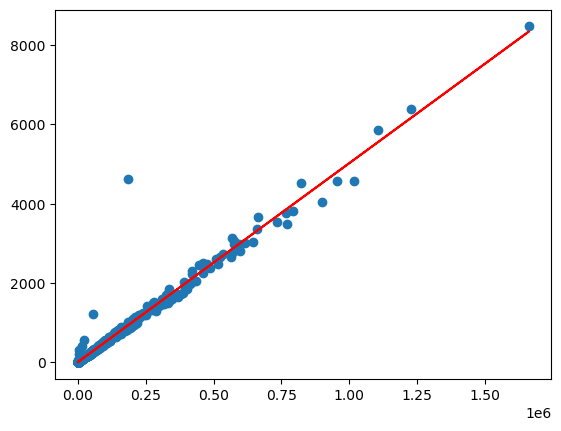

In [121]:
# we are checking the the test data with best fitting straight line

plt.scatter(X_test, y_test)
plt.plot(X_test, model1.predict(X_test),color = 'red')

In [123]:
# inferencing 

input_data = {"Dollars" : [18500]}

df = pd.DataFrame(input_data)

In [118]:
model1.predict(df)

array([97.78868161])